## **Imports**

In [ ]:
!pip install ucmlrepo xgboost shap reportlab


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import math
import random
import itertools
from ucimlrepo import fetch_ucirepo
import shap

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from xgboost import XGBClassifier

In [ ]:
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle
)
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib.pagesizes import A4
from reportlab.lib import colors
from reportlab.platypus import Image

## **Dataset**

In [ ]:
# fetch dataset
maternal_health_risk = fetch_ucirepo(id=863)

# data (as pandas dataframes)
X = maternal_health_risk.data.features
y = maternal_health_risk.data.targets

# metadata
print(maternal_health_risk.metadata)

# variable information
print(maternal_health_risk.variables)


{'uci_id': 863, 'name': 'Maternal Health Risk', 'repository_url': 'https://archive.ics.uci.edu/dataset/863/maternal+health+risk', 'data_url': 'https://archive.ics.uci.edu/static/public/863/data.csv', 'abstract': 'Data has been collected from different hospitals, community clinics, maternal health cares from the rural areas of Bangladesh through the IoT based risk monitoring system.', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 1013, 'num_features': 6, 'feature_types': ['Real', 'Integer'], 'demographics': ['Age'], 'target_col': ['RiskLevel'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2020, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C5DP5D', 'creators': ['Marzia Ahmed'], 'intro_paper': {'ID': 274, 'type': 'NATIVE', 'title': 'Review and Analysis of Risk Factor of Maternal Health in Remote Area Using the Internet of Things (IoT)', 'authors':

In [ ]:
df = pd.concat([X, y], axis=1)
print(df.head())

   Age  SystolicBP  DiastolicBP    BS  BodyTemp  HeartRate  RiskLevel
0   25         130           80  15.0      98.0         86  high risk
1   35         140           90  13.0      98.0         70  high risk
2   29          90           70   8.0     100.0         80  high risk
3   30         140           85   7.0      98.0         70  high risk
4   35         120           60   6.1      98.0         76   low risk


In [ ]:
print("Shape of dataset:", df.shape)
print("Number of rows:", len(df))
print("Number of features (excluding target):", df.shape[1] - 1)
print("\nColumn names:")
print(df.columns.tolist())


Shape of dataset: (1014, 7)
Number of rows: 1014
Number of features (excluding target): 6

Column names:
['Age', 'SystolicBP', 'DiastolicBP', 'BS', 'BodyTemp', 'HeartRate', 'RiskLevel']


## **Visualization**

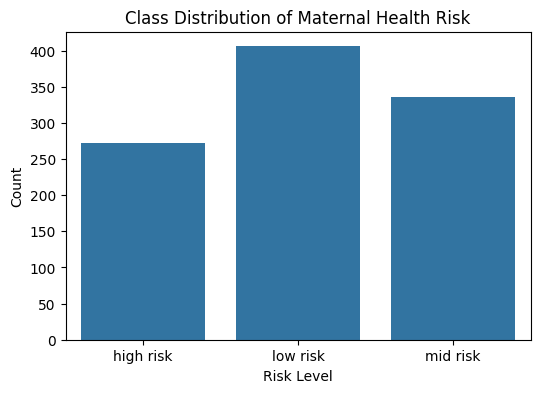

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="RiskLevel")
plt.title("Class Distribution of Maternal Health Risk")
plt.xlabel("Risk Level")
plt.ylabel("Count")
plt.show()


## **Preprocessing**

In [ ]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())


Missing values per column:
Age            0
SystolicBP     0
DiastolicBP    0
BS             0
BodyTemp       0
HeartRate      0
RiskLevel      0
dtype: int64

Number of duplicate rows: 562


In [ ]:
# Clean labels
df["RiskLevel"] = df["RiskLevel"].str.strip().str.lower()

risk_mapping = {
    "low risk": 0,
    "mid risk": 1,
    "high risk": 2
}

df["RiskLevel"] = df["RiskLevel"].map(risk_mapping)

print("Mapped target distribution:")
print(df["RiskLevel"].value_counts())


Mapped target distribution:
RiskLevel
0    406
1    336
2    272
Name: count, dtype: int64


In [ ]:
X = df.drop(columns=["RiskLevel"])
y = df["RiskLevel"]


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train target distribution:")
print(y_train.value_counts())

print("\nTest target distribution:")
print(y_test.value_counts())


Train target distribution:
RiskLevel
0    325
1    269
2    217
Name: count, dtype: int64

Test target distribution:
RiskLevel
0    81
1    67
2    55
Name: count, dtype: int64


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Scaled train shape: (811, 6)


## **Models**

In [ ]:
lr = LogisticRegression(
    multi_class="multinomial",
    solver="lbfgs",
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


In [ ]:
svm = SVC(
    kernel="rbf",
    probability=True,
    class_weight="balanced",
    random_state=42
)

svm.fit(X_train_scaled, y_train)

y_pred_svm = svm.predict(X_test_scaled)


In [ ]:
xgb = XGBClassifier(
    objective="multi:softprob",
    num_class=3,
    eval_metric="mlogloss",
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_test)


In [ ]:
models = {
    "Logistic Regression": y_pred_lr,
    "SVM": y_pred_svm,
    "XGBoost": y_pred_xgb
}

results = []

for model_name, y_pred in models.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Recall (Low)": recall_score(y_test, y_pred, labels=[0], average=None)[0],
        "Recall (Mid)": recall_score(y_test, y_pred, labels=[1], average=None)[0],
        "Recall (High)": recall_score(y_test, y_pred, labels=[2], average=None)[0],
        "Precision (Low)": precision_score(y_test, y_pred, labels=[0], average=None)[0],
        "Precision (Mid)": precision_score(y_test, y_pred, labels=[1], average=None)[0],
        "Precision (High)": precision_score(y_test, y_pred, labels=[2], average=None)[0],
    })

results_df = pd.DataFrame(results)
print(results_df)


                 Model  Accuracy  Recall (Low)  Recall (Mid)  Recall (High)  \
0  Logistic Regression  0.630542      0.654321      0.417910       0.854545   
1                  SVM  0.694581      0.827160      0.358209       0.909091   
2              XGBoost  0.852217      0.851852      0.761194       0.963636   

   Precision (Low)  Precision (Mid)  Precision (High)  
0         0.654321         0.466667          0.758065  
1         0.656863         0.631579          0.793651  
2         0.841463         0.822581          0.898305  


## **Instance**

In [ ]:
X_instance=X_test.iloc[[1]]
print(X_instance)

instance_pred=xgb.predict(X_instance)[0]
print(instance_pred)

instance_prob=xgb.predict_proba(X_instance)[0][instance_pred]
print(instance_prob)

instance_age = X_instance['Age']
print(instance_age)

     Age  SystolicBP  DiastolicBP   BS  BodyTemp  HeartRate
141   17          90           60  6.9     101.0         76
1
0.8870668
141    17
Name: Age, dtype: int64


## **Explanations TreeSHAP**

In [ ]:
# Initialize TreeSHAP explainer
explainer = shap.TreeExplainer(xgb)

In [ ]:
def shap_explain(point,ml_model,explainer):
  shap_values=explainer.shap_values(point)
  #print(shap_values.shape)
  cls_inx=int(ml_model.predict(point)[0])
  shap_values_cls=shap_values[0, :, cls_inx]
  base_value_cls = explainer.expected_value[cls_inx]
  return shap_values_cls, base_value_cls, cls_inx
'''
def bar_explain(shap_values_class,data):
  shap.bar_plot(shap_values_class,feature_names=data.columns)
'''

def bar_explain(shap_values_class, data, save_path=None):
    plt.figure(figsize=(6, 4))
    shap.bar_plot(shap_values_class,feature_names=data.columns,show=False)
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()
    plt.close()


def influence(shap_array,data):
  shap_df=pd.DataFrame({'feature':data.columns,'SHAP_value':shap_array})
  top_positive = shap_df.sort_values(by="SHAP_value",ascending=False)
  return top_positive


(array([ 0.26419243,  0.07034231,  0.09764044,  0.75495774,  0.17402886,
       -0.01943079], dtype=float32), np.float32(0.1230892), 1)


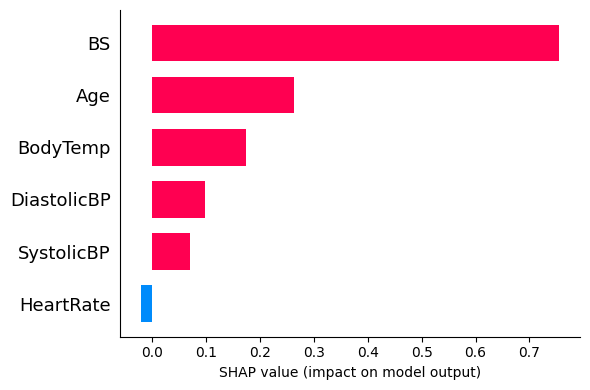

       feature  SHAP_value
3           BS    0.754958
0          Age    0.264192
4     BodyTemp    0.174029
2  DiastolicBP    0.097640
1   SystolicBP    0.070342
5    HeartRate   -0.019431


In [ ]:
explanation=shap_explain(X_instance,xgb,explainer)
print(explanation)

#bar_explain(explanation[0],X_train)

shap_img_path = "shap_bar.png"
bar_explain(explanation[0], X_train, save_path=shap_img_path)

top_f=influence(explanation[0],X_train)
print(top_f)

## **Risk Mitigation**

In [ ]:
# Immutable features (should not be changed)
immutable_features = ["Age"]

# Mutable features
mutable_features = [col for col in X.columns if col not in immutable_features]
print(mutable_features)

['SystolicBP', 'DiastolicBP', 'BS', 'BodyTemp', 'HeartRate']


In [ ]:
neighbours=[]

if(instance_pred==0):
  # When the risk level is the least
  for i in range(0,len(X_train)):
    point = X_train.iloc[i].values.reshape(1, -1)  # UNscaled
    pred = xgb.predict(point)[0]
    # Same predicted class 0
    if pred == instance_pred:
      pred_prob = xgb.predict_proba(point)[0][pred]
        # Lower confidence than the instance
      if pred_prob < instance_prob:
        point_age=point[0][0]
        valid_age_diff=abs(point_age - instance_age.iloc[0])
        if(valid_age_diff < 3):
          neighbours.append(point[0])

else:
  # For all other risk levels
  instance_dist = instance_prob - xgb.predict_proba(X_instance)[0][instance_pred-1]
  for i in range(0,len(X_train)):
    point = X_train.iloc[i].values.reshape(1,-1)
    pred = xgb.predict(point)[0]
    #same predicted class 1 or 2
    if pred == instance_pred:
      pred_prob = xgb.predict_proba(point)[0][pred]
      pred_prob_prev = xgb.predict_proba(point)[0][pred-1]
      #diff b/w its safer class
      dist=pred_prob-pred_prob_prev
      if(dist<instance_dist):
        point_age=point[0][0]
        valid_age_diff=abs(point_age - instance_age.iloc[0])
        if(valid_age_diff < 3):
          neighbours.append(point[0])

if(len(neighbours)==0):
  print("nothing")
else:
  new_instance=np.sum(neighbours,axis=0)
  new_instance=new_instance/len(neighbours)
  new_instance=np.round(new_instance, 3)

new_instance = new_instance.tolist()
print(new_instance)


[18.125, 110.859, 75.0, 7.203, 99.0, 72.688]


In [ ]:
instance_probabilities = xgb.predict_proba(X_instance)[0]
new_probabilities = xgb.predict_proba([new_instance])[0]

print(instance_probabilities)
print(new_probabilities)

delta = []
for i in range(0, len(X_instance.columns)):
  col=X_instance.columns[i]
  delta.append(new_instance[i]-X_instance.iloc[0][col])

print(delta)

[0.07504369 0.8870668  0.0378896 ]
[0.9132296  0.07835145 0.00841898]
[np.float64(1.125), np.float64(20.858999999999995), np.float64(15.0), np.float64(0.30299999999999994), np.float64(-2.0), np.float64(-3.3119999999999976)]


## **Weighted-SHAP based approach**

In [ ]:
shap_weights=abs(explanation[0])
print(shap_weights)

shap_norms = shap_weights/sum(shap_weights)
print(shap_norms)

[0.26419243 0.07034231 0.09764044 0.75495774 0.17402886 0.01943079]
[0.19136164 0.05095081 0.07072358 0.5468361  0.12605375 0.01407424]


In [ ]:
MAX_STEP={}
for f in X_train.columns:
  if(f=='Age'):
    continue
  MAX_STEP[f] = X_train[f].std()

print(MAX_STEP)

{'SystolicBP': 18.43574397355553, 'DiastolicBP': 13.798967768292263, 'BS': 3.204997218586902, 'BodyTemp': 1.3728506625674743, 'HeartRate': 8.276927980904697}


In [ ]:
feasable_point=[]
for i in range(0,len(X_train.columns)):
  f = X_train.columns[i]
  if(f not in MAX_STEP):
    continue

  step_size = MAX_STEP[f]*shap_norms[i]
  direction = np.sign(delta[i])
  step = direction * min(abs(delta[i]), step_size)

  feasable_point.append(float(round(step + X_instance.iloc[0][f],3)))

feasable_point.insert(0, float(new_instance[0]))

print(feasable_point)

[18.125, 90.939, 60.976, 7.203, 100.827, 75.884]


In [ ]:
intermediate_probabilities=xgb.predict_proba([feasable_point])[0]
print(intermediate_probabilities)

[0.8506717  0.12414458 0.02518367]


### **Result**

In [ ]:
print(list(X_instance.iloc[0]))
print(list(feasable_point))
print(new_instance)

print(instance_probabilities)
print(intermediate_probabilities)
print(new_probabilities)

[17.0, 90.0, 60.0, 6.9, 101.0, 76.0]
[18.125, 90.939, 60.976, 7.203, 100.827, 75.884]
[18.125, 110.859, 75.0, 7.203, 99.0, 72.688]
[0.07504369 0.8870668  0.0378896 ]
[0.8506717  0.12414458 0.02518367]
[0.9132296  0.07835145 0.00841898]


## **Report Formulation**

### **Feature Metadata**

In [ ]:
FEATURE_META = {
    "Age": {
        "type": "immutable",
        "unit": "years",
        "description": "Age is a non-modifiable demographic factor."
    },

    "SystolicBP": {
        "type": "vital",
        "unit": "mmHg",
        "direction": "lower_is_better",
        "ranges": [
            (0, 89, "Hypotension"),
            (90, 119, "Normal"),
            (120, 129, "Elevated"),
            (130, 139, "Hypertension (Stage 1)"),
            (140, 159, "Hypertension (Stage 2)"),
            (160, float("inf"), "Severe hypertension")
        ]
    },

    "DiastolicBP": {
        "type": "vital",
        "unit": "mmHg",
        "direction": "lower_is_better",
        "ranges": [
            (0, 59, "Hypotension"),
            (60, 79, "Normal"),
            (80, 89, "Hypertension (Stage 1)"),
            (90, 99, "Hypertension (Stage 2)"),
            (100, float("inf"), "Severe hypertension")
        ]
    },

    "BS": {
        "type": "lab",
        "unit": "mmol/L",
        "direction": "lower_is_better",
        "ranges": [
            (0, 3.3, "Hypoglycemia"),
            (3.3, 5.1, "Normal"),
            (5.1, 11.0, "Moderate hyperglycemia"),
            (11.0, float("inf"), "Severe hyperglycemia")
        ]
    },

    "BodyTemp": {
        "type": "vital",
        "unit": "°F",
        "direction": "around 98.6",
        "ranges": [
            (0, 95.0, "Hypothermia"),
            (95.0, 97.0, "Low body temperature"),
            (97.0, 99.0, "Normal"),
            (99.0, 100.4, "Elevated temperature"),
            (100.4, float("inf"), "Fever")
        ]
    },

    "HeartRate": {
        "type": "vital",
        "unit": "bpm",
        "direction": "moderate_range",
        "ranges": [
            (0, 59, "Bradycardia"),
            (60, 99, "Normal"),
            (100, 119, "Mild tachycardia"),
            (120, float("inf"), "Severe tachycardia")
        ],
        "note": "Slightly elevated heart rate can be normal during pregnancy."
    }
}


### **Helper Scripts**

In [ ]:
if(instance_pred==0):
  model_class='low'
  conc = (
  "The model indicates a low maternal health risk. "
  "Maintaining healthy lifestyle practices and routine monitoring is recommended."
)
elif(instance_pred==1):
  model_class='mid'
  conc = (
  "The model indicates a medium maternal health risk. "
  "Routine monitoring is recommended. Please schedule an appointment with the doctor for a follow-up."
)
else:
  model_class='high'
  conc = (
  "The model indicates a high maternal health risk."
  "It is advised that immediate medical attention be given."
)

In [ ]:
feasible_point_series = pd.Series(
    feasable_point,
    index=X_instance.columns
)

sorted_feat=influence(explanation[0],X_train)
f_list=[]
for i in range(0,2):
  f_list.append(sorted_feat.iloc[i]['feature'])
if 'Age' in f_list:
  f_list.append(sorted_feat.iloc[3]['feature'])
print(f_list)

condition=[]
for feat in f_list:
  if(feat=='Age'):
    continue
  val=X_instance.iloc[0][feat]
  label1=None
  print(val)
  for low,high,ele in (FEATURE_META[feat]["ranges"]):
    if low <= val < high :
      label1=ele
      condition.append((feat, label1, val))
      break


print(condition)

['BS', 'Age', 'DiastolicBP']
6.9
60.0
[('BS', 'Moderate hyperglycemia', np.float64(6.9)), ('DiastolicBP', 'Normal', np.float64(60.0))]


### **Helper Functions**

In [ ]:
def generate_observations(X_instance, feasible_point, FEATURE_META):
    observations = []

    for feat in FEATURE_META:
        if feat == "Age":
            continue

        curr = X_instance.iloc[0][feat]
        target = feasible_point[feat]   # now works

        curr_label = get_clinical_label(feat, curr, FEATURE_META)
        target_label = get_clinical_label(feat, target, FEATURE_META)

        if curr_label != target_label:
            obs = (
                f"{feat} is currently {curr} ({curr_label}). "
                f"Reducing it to approximately {round(target,2)} would move it into "
                f"the {target_label} range, which may lower maternal risk."
            )
            observations.append(obs)

    if not observations:
        observations.append(
            "All major clinical parameters are within acceptable ranges. "
            "Continued monitoring is advised."
        )

    return observations

In [ ]:
def generate_lifestyle_recommendations(condition):
    lifestyle = []

    for feat, label, val in condition:
        if label is None:
            continue

        if feat in ["SystolicBP", "DiastolicBP"] and "Hyper" in label:
            lifestyle.append(
                "Reduce dietary sodium intake, avoid processed foods, "
                "and engage in light physical activity such as walking, "
                "as advised by a healthcare provider."
            )

        if feat == "BS" and "hyperglycemia" in label.lower():
            lifestyle.append(
                "Adopt small, frequent meals with low glycemic index foods, "
                "limit refined sugars, and monitor blood glucose regularly."
            )

        if feat == "BodyTemp" and label == "Fever":
            lifestyle.append(
                "Ensure adequate hydration, rest, and avoid overheating. "
                "Seek medical advice if fever persists."
            )

        if feat == "HeartRate" and "tachycardia" in label.lower():
            lifestyle.append(
                "Ensure adequate hydration, manage stress levels, "
                "and avoid excessive caffeine intake."
            )

    if not lifestyle:
        lifestyle.append(
            "Maintain a balanced diet, adequate hydration, regular prenatal check-ups, "
            "and sufficient rest."
        )

    return list(set(lifestyle))

In [ ]:
def generate_medical_guidance(model_class, condition):
    guidance = []

    if model_class == "high":
        guidance.append(
            "Immediate medical evaluation is recommended. "
            "Hospital-based monitoring may be required."
        )

    elif model_class == "mid":
        guidance.append(
            "Schedule a follow-up appointment with an obstetrician "
            "for further clinical evaluation."
        )

    for feat, label, val in condition:
        if label in ["Severe hypertension", "Severe hyperglycemia", "Fever"]:
            guidance.append(
                f"{feat} indicates {label}. Prompt clinical assessment "
                "and potential medical intervention may be necessary."
            )

    guidance.append(
        "All medications should be taken strictly under medical supervision, "
        "especially during pregnancy."
    )

    return list(set(guidance))

In [ ]:
def get_clinical_label(feature, value, meta):
    if "ranges" not in meta[feature]:
        return None

    for low, high, label in meta[feature]["ranges"]:
        if low <= value < high:
            return label

    return "Unknown"

### **Report Format**

In [ ]:
#top left side
patient_info={
    'Name' : 'XYZ',
    'Age (years)' : X_instance.iloc[0]['Age'],
    'SystolicBP (mmHg)' : X_instance.iloc[0]['SystolicBP'],
    'DiastolicBP (mmHg)' : X_instance.iloc[0]['DiastolicBP'],
    'BloodSugar (mmol/g)' : X_instance.iloc[0]['BS'],
    'BodyTemperature (F)' : X_instance.iloc[0]['BodyTemp'],
    'HeartRate (bpm)' : X_instance.iloc[0]['HeartRate']
}

#top right side
model_predictions={
    'model_output' : model_class,
    'model_probability' : instance_prob,
    'top_contributions' : influence(explanation[0],X_train)
}
#bar_explain(explanation[0],X_train)

#next section -> textual format of the current condition -> like a summary
risk_summary={
    'risk_statement' : f"The patient is classified as {model_class}-risk based on current clinical parameters.",
    'key_risk_drivers' : f"The following are expected to contribute to the risk: {f_list}",
    'other_complications' : [f"{condition[0][0]} has a value {condition[0][2]} indicating {condition[0][1]}",
                             f"{condition[1][0]} has a value {condition[1][2]} indicating {condition[1][1]}"]
}

# next section -> nearby points
recommended_targets={'short_term_target' : feasable_point, 'long_term_target' : new_instance}

#next section -> textual interpretation - if BP reduces from A to B....
observations = {"clinical_observations": generate_observations(X_instance, feasible_point_series, FEATURE_META)}

#next section -> actions recommended (lifestyle)
lifestyle = {"recommended_lifestyle_changes": generate_lifestyle_recommendations(condition)}

#next section -> medicines and medical help
medical = {"medical_guidance": generate_medical_guidance(model_class, condition)}

#last section -> conclusion and disclamer
conclusion={
    'disclaimer': conc,
    'exit' : (
        "This report is generated using a machine learning model and is intended "
        "to support, not replace, clinical judgment."
    )
}


In [ ]:
report = {
    "patient_info": patient_info,
    "model_predictions": model_predictions,
    "risk_summary": risk_summary,
    "observations": observations,
    "lifestyle": lifestyle,
    "medical": medical,
    "conclusion": conclusion
}

print(report)

{'patient_info': {'Name': 'XYZ', 'Age (years)': np.float64(17.0), 'SystolicBP (mmHg)': np.float64(90.0), 'DiastolicBP (mmHg)': np.float64(60.0), 'BloodSugar (mmol/g)': np.float64(6.9), 'BodyTemperature (F)': np.float64(101.0), 'HeartRate (bpm)': np.float64(76.0)}, 'model_predictions': {'model_output': 'mid', 'model_probability': np.float32(0.8870668), 'top_contributions':        feature  SHAP_value
3           BS    0.754958
0          Age    0.264192
4     BodyTemp    0.174029
2  DiastolicBP    0.097640
1   SystolicBP    0.070342
5    HeartRate   -0.019431}, 'risk_summary': {'risk_statement': 'The patient is classified as mid-risk based on current clinical parameters.', 'key_risk_drivers': "The following are expected to contribute to the risk: ['BS', 'Age', 'DiastolicBP']", 'other_complications': ['BS has a value 6.9 indicating Moderate hyperglycemia', 'DiastolicBP has a value 60.0 indicating Normal']}, 'observations': {'clinical_observations': ['All major clinical parameters are with

## **Report Generation**

In [ ]:
def section_title(text, styles):
    return Paragraph(f"<b><font size=14>{text}</font></b>", styles["Heading2"])

def bullet_list(items, styles):
    return [Paragraph(f"• {item}", styles["Normal"]) for item in items]

def patient_info_table(patient_info):
    data = [[k, str(v)] for k, v in patient_info.items()]

    table = Table(data, colWidths=[180, 200])
    table.setStyle(TableStyle([
        ('BACKGROUND', (0,0), (-1,0), colors.whitesmoke),
        ('GRID', (0,0), (-1,-1), 0.5, colors.grey),
        ('FONT', (0,0), (-1,-1), 'Helvetica'),
        ('VALIGN', (0,0), (-1,-1), 'MIDDLE')
    ]))

    return table


In [ ]:
def generate_pdf_report(
    filename,
    patient_info,
    model_predictions,
    risk_summary,
    observations,
    lifestyle,
    medical,
    conclusion,
    shap_image_path
):
    doc = SimpleDocTemplate(filename, pagesize=A4)
    styles = getSampleStyleSheet()
    story = []

    # ================= TITLE =================
    story.append(Paragraph(
        "<b><font size=18>Maternal Health Risk Assessment Report</font></b>",
        styles["Title"]
    ))
    story.append(Spacer(1, 12))

    # ================= PATIENT INFO =================
    story.append(section_title("Patient Information", styles))
    story.append(Spacer(1, 6))
    story.append(patient_info_table(patient_info))
    story.append(Spacer(1, 14))

    # ================= MODEL PREDICTION =================
    story.append(section_title("Model Prediction", styles))
    story.append(Paragraph(
        f"Predicted Risk Category: <b>{model_predictions['model_output'].upper()}</b>",
        styles["Normal"]
    ))
    story.append(Paragraph(
        f"Prediction Confidence: {round(model_predictions['model_probability'], 3)}",
        styles["Normal"]
    ))
    story.append(Spacer(1, 12))

    # ================= SHAP EXPLANATION =================
    story.append(section_title("Model Explainability (SHAP)", styles))
    story.append(Spacer(1, 6))

    story.append(Image(
        shap_image_path,
        width=400,
        height=280
    ))

    story.append(Spacer(1, 8))
    story.append(Paragraph(
        "The SHAP bar plot above illustrates the relative contribution of each "
        "clinical feature to the model's risk prediction for this patient.",
        styles["Normal"]
    ))
    story.append(Spacer(1, 14))

    # ================= RISK SUMMARY =================
    story.append(section_title("Risk Summary", styles))

    story.append(Paragraph(
        risk_summary["risk_statement"],
        styles["Normal"]
    ))
    story.append(Spacer(1, 4))

    story.append(Paragraph(
        risk_summary["key_risk_drivers"],
        styles["Normal"]
    ))
    story.append(Spacer(1, 6))

    # Other complications (bullet list)
    if "other_complications" in risk_summary:
        for comp in risk_summary["other_complications"]:
            story.append(Paragraph(f"• {comp}", styles["Normal"]))

    story.append(Spacer(1, 14))

    # ================= OBSERVATIONS =================
    story.append(section_title("Clinical Observations", styles))
    for p in bullet_list(observations["clinical_observations"], styles):
        story.append(p)
    story.append(Spacer(1, 14))

    # ================= LIFESTYLE =================
    story.append(section_title("Lifestyle Recommendations", styles))
    for p in bullet_list(lifestyle["recommended_lifestyle_changes"], styles):
        story.append(p)
    story.append(Spacer(1, 14))

    # ================= MEDICAL =================
    story.append(section_title("Medical Guidance", styles))
    for p in bullet_list(medical["medical_guidance"], styles):
        story.append(p)
    story.append(Spacer(1, 14))

    # ================= DISCLAIMER =================
    story.append(section_title("Conclusion & Disclaimer", styles))
    story.append(Paragraph(conclusion["disclaimer"], styles["Normal"]))
    story.append(Spacer(1, 6))
    story.append(Paragraph(conclusion["exit"], styles["Italic"]))

    # ================= BUILD =================
    doc.build(story)


In [ ]:
generate_pdf_report(
    filename="maternal_health_report.pdf",
    patient_info=patient_info,
    model_predictions=model_predictions,
    risk_summary=risk_summary,
    observations=observations,
    lifestyle=lifestyle,
    medical=medical,
    conclusion=conclusion,
    shap_image_path="/content/shap_bar.png"
)
